# Solidification beyond Scheil: diffusion in the solid with janus-kinetics

pycalphad, with its companion `scheil` package, gives the two classic limits of solidification: the lever
rule (full equilibrium) and the Scheil-Gulliver path (no diffusion in the solid). Real castings lie between them, depending on how fast
the solid can diffuse while it forms. [janus-kinetics](https://github.com/odinzen/janus-kinetics)
([doi:10.5281/zenodo.23381870](https://doi.org/10.5281/zenodo.23381870)) is built to work with pycalphad:
it takes the thermodynamics from a pycalphad `Database` and adds the kinetics.

This example follows a Ni-18Al-2Cr (at.%) alloy, whose last liquid forms gamma' on the Scheil path, and
shows how much gamma' survives when the solid diffuses as it grows. The thermodynamics are the Al-Cr-Ni
description of Dupin, Ansara and Sundman (Calphad 25 (2001) 279) in `alcrni.tdb`, the same file as
pycalphad's test database. The diffusion uses the Ni-base mobilities of Campbell, Boettinger and Kattner
(Acta Mater. 50 (2002) 775), which ship with janus-kinetics.

Install with `pip install git+https://github.com/odinzen/janus-kinetics`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from pycalphad import Database, equilibrium, variables as v

from janus_kinetics import SolutionPhase, TemperatureSchedule, campbell2002_fcc_ni
from janus_kinetics.dendrite_tip import liquidus
from janus_kinetics.solidification import equilibrium_start, scheil_gulliver, solve_solidification_to_end

warnings.filterwarnings("ignore")  # pycalphad's TYPE_DEFINITION notes and the magnetic-model reminder

db = Database("alcrni.tdb")
comps = ["AL", "CR", "NI"]  # Ni last: it is the dependent element
alloy = [0.18, 0.02]  # mole fractions of Al and Cr

## The liquidus and the equilibrium (lever-rule) path

janus-kinetics wraps the phases it needs from the same database: the primary gamma (FCC_A1), with its
mobilities, and the liquid. The liquidus comes from equal chemical potentials of every element in
the two phases; the equilibrium path is plain pycalphad.

In [2]:
gamma = SolutionPhase(db, "FCC_A1", comps, mobility_db=campbell2002_fcc_ni())
melt = SolutionPhase(db, "LIQUID", comps, mobilities=False)
t_liquidus = liquidus(gamma, melt, alloy, 1680.0).temperature
print(f"liquidus {t_liquidus:.1f} K")

temps = np.arange(np.floor(t_liquidus), 1560.0, -1.0)
eq = equilibrium(db, comps + ["VA"], ["LIQUID", "L12_FCC"],
                 {v.T: temps, v.P: 101325, v.N: 1, v.X("AL"): alloy[0], v.X("CR"): alloy[1]})
phase, amount = np.squeeze(eq.Phase.values), np.squeeze(eq.NP.values)
lever = 1 - np.nansum(np.where(phase == "LIQUID", amount, 0.0), axis=-1)

liquidus 1681.4 K


## The Scheil-Gulliver path, with gamma and gamma' told apart

In this database gamma and gamma' are one L1_2 model, and pycalphad names both L12_FCC. The `disordered`
argument labels composition sets whose sublattices hold the same fractions as FCC_A1 (gamma), so only
ordered gamma' keeps the name L12_FCC.

In [3]:
ordered = {"L12_FCC": "FCC_A1"}
scheil = scheil_gulliver(db, comps, ["LIQUID", "L12_FCC"], alloy, t_liquidus + 1, 1.0,
                         stop_fraction=1e-3, t_min=1500.0, disordered=ordered)
first = next(T for T, step in zip(scheil.temperatures[1:], scheil.solids) for name, _, _ in step if name == "L12_FCC")
print(f"gamma' first forms at {first:.1f} K; Scheil gamma' fraction {scheil.solid_phase_fractions()['L12_FCC']:.4f}")

gamma' first forms at 1615.4 K; Scheil gamma' fraction 0.0638


## Back-diffusion: the solid diffuses as it grows

`solve_solidification_to_end` grows the primary gamma from the centre of a volume element, half a
secondary dendrite arm spacing wide (25 um here), with local equilibrium at the solid/liquid interface and
a uniform liquid, while the temperature falls at a constant rate. Every degree it checks whether the liquid
would form another solid; once gamma' appears, solid diffusion is dropped and the rest of the liquid
follows the Scheil path, as Kattner, Boettinger and Coriell (Z. Metallkd. 87 (1996) 522) treat the
eutectic. For speed the solid's interdiffusion matrix is taken once, from Campbell's mobilities near
the solidus (1650 K).

In [4]:
d_solid = gamma.interdiffusion_matrix([0.16, 0.018], 1650.0)
print("interdiffusion matrix of gamma at 1650 K (m^2/s):\n", d_solid)
start = equilibrium_start(db, comps, "FCC_A1", "LIQUID", alloy, t_liquidus - 0.5)

def solidify(rate, span=120.0):
    """Back-diffusion at a cooling rate in K/s, handed to Scheil once gamma' forms."""
    cooling = TemperatureSchedule([0.0, span / rate], [t_liquidus - 0.5, t_liquidus - 0.5 - span])
    return solve_solidification_to_end(db, ["LIQUID", "L12_FCC"], gamma, melt, cooling, span / rate, 25e-6, start,
                                       step=1.0, solid_diffusivity=d_solid, cells=40, dt=0.2 / rate,
                                       disordered=ordered)

runs = {rate: solidify(rate) for rate in (1000.0, 100.0, 30.0, 10.0)}

interdiffusion matrix of gamma at 1650 K (m^2/s):
 [[2.87696066e-12 1.59494653e-12]
 [2.03264156e-13 6.44814141e-13]]


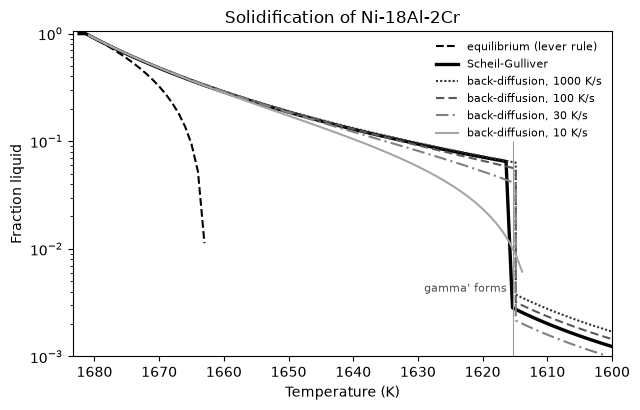

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
floor = 1e-3  # the paths part in the last few percent of liquid, so the liquid is drawn on a log scale

def liquid(fraction_solid):
    f = 1 - np.asarray(fraction_solid)
    return np.where(f > floor, f, np.nan)  # no line where the liquid is gone

ax.semilogy(temps, liquid(lever), "k--", label="equilibrium (lever rule)")
ax.semilogy(scheil.temperatures, liquid(scheil.fraction_solid), "k-", lw=2.4, label="Scheil-Gulliver")
styles = {1000.0: (0, (1, 1)), 100.0: (0, (4, 2)), 30.0: (0, (6, 2, 1, 2)), 10.0: "-"}
greys = {1000.0: "0.2", 100.0: "0.35", 30.0: "0.5", 10.0: "0.65"}
for rate, run in runs.items():
    ax.semilogy(run.temperatures, liquid(run.fraction_solid), linestyle=styles[rate],
                color=greys[rate], label=f"back-diffusion, {rate:g} K/s")
ax.vlines(first, floor, 0.1, color="0.6", lw=0.8)
ax.annotate("gamma' forms", (first, 0.004), xytext=(-4, 0), textcoords="offset points", fontsize=8, color="0.3",
            ha="right")
ax.set_xlim(1600, t_liquidus + 2)
ax.set_ylim(floor, 1.05)
ax.invert_xaxis()
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Fraction liquid")
ax.set_title("Solidification of Ni-18Al-2Cr")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()

In [6]:
print(f"{'path':<28}{'gamma prime':>12}")
print(f"{'Scheil-Gulliver':<28}{scheil.solid_phase_fractions()['L12_FCC']:>12.4f}")
for rate, run in runs.items():
    gp = run.phase_fractions().get("L12_FCC", 0.0)
    print(f"{f'back-diffusion {rate:g} K/s':<28}{gp:>12.4f}")
print(f"{'equilibrium':<28}{0.0:>12.4f}")

path                         gamma prime
Scheil-Gulliver                   0.0638
back-diffusion 1000 K/s           0.0623
back-diffusion 100 K/s            0.0548
back-diffusion 30 K/s             0.0400
back-diffusion 10 K/s             0.0000
equilibrium                       0.0000


Diffusion in the solid lets the primary gamma take up Al that the Scheil path leaves in the liquid, so the
last liquid is less enriched and less gamma' forms: from the Scheil value at fast cooling down to none at
10 K/s, where the solid keeps up and freezing ends as gamma alone, as on the equilibrium path.

Assumptions worth knowing: a plate-like volume element (cylinders and spheres are options), a fixed
interdiffusion matrix, a uniform liquid, and no undercooling at the dendrite tip (janus-kinetics also has
a tip model). The back-diffusion solver stops when its liquid layer falls below about 2 % of its starting
thickness and no longer converges; the remaining liquid then counts as liquid in the totals, which the
10 K/s run reaches with well under 1 % left.

The models, their sources and how each is checked against its paper are in the
[janus-kinetics documentation](https://github.com/odinzen/janus-kinetics/blob/main/docs/validation.md).